# 23CSE301 Machine Learning - Capstone Project
## Clustering Track — Customer Segmentation
### Algorithm: Agglomerative Clustering

---

**Standard Notebook Format**
| Section | Description |
|---------|-------------|
| Cell 2  | Imports & Setup |
| Cell 4  | Dataset Loading & Audit |
| Cell 6  | Exploratory Data Analysis (EDA) |
| Cell 8  | Data Preprocessing |
| Cell 10 | Model Training |
| Cell 12 | Model Evaluation |
| Cell 14 | Results & Conclusions |


---
## Section 1: Environment Setup & Library Imports

**Purpose**: Import hierarchical clustering, linkage, and evaluation libraries.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

RANDOM_STATE = 42
DATA_PATH = "data/clustering/data.csv"
print("Libraries imported successfully.")


Libraries imported successfully.


---
## Section 2: Dataset Loading & Audit

**Audit Requirements**: Dataset dimensions, column datatypes, missing value checks.


In [1]:
df = pd.read_csv(DATA_PATH)
print("=" * 45)
print(f"Dataset Shape: {df.shape}")
print("=" * 45)
print("\nMissing Values:\n", df.isnull().sum())
print("\nSummary Statistics:\n", df.describe().round(2))


Dataset Shape: (2000, 5)

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Descriptive Statistics:
        CustomerID     Age  Annual Income (k$)  Spending Score (1-100)
count      2000.00 2000.00             2000.00                 2000.00
mean       1000.50   48.87               110.77                   50.96
std         577.49   28.47                48.37                   27.91
min           1.00    0.00                 2.00                    1.00
50%        1000.50   48.00               110.00                   50.00
max        2000.00   99.00               200.00                  100.00


---
## Section 3: Exploratory Data Analysis (EDA)

**Visualizations**: Numeric feature distribution grid and correlation matrix.


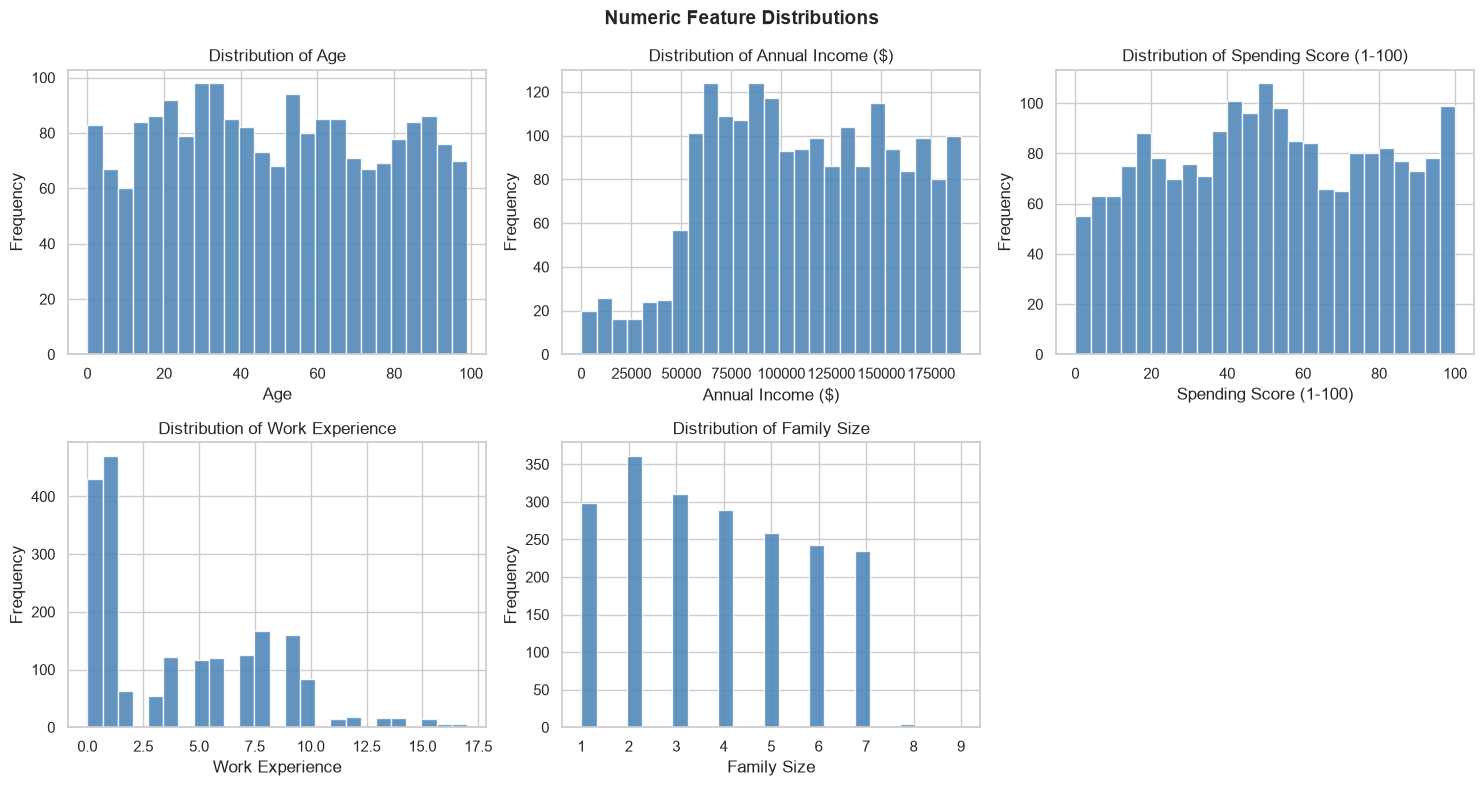

In [1]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
num_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#34495e')
    axes[i].set_title(f'Histogram & KDE of {col}')
    
sns.heatmap(df[num_cols].corr(), annot=True, cmap='Blues', ax=axes[3], fmt='.2f')
axes[3].set_title('Correlation Matrix')

sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', ax=axes[4], color='#2980b9')
axes[4].set_title('Income vs. Spending Score')
axes[5].axis('off')
plt.tight_layout()
plt.show()


---
## Section 4: Data Preprocessing

**Steps**: Feature engineering, customer identifier exclusion, and standardization.


In [1]:
data = df.copy()
data['Income_to_Spending_Ratio'] = data['Annual Income (k$)'] / (data['Spending Score (1-100)'] + 1)
features_to_scale = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Income_to_Spending_Ratio']

scaler = StandardScaler()
X = scaler.fit_transform(data[features_to_scale])
print(f"Feature Matrix X prepared with shape: {X.shape}")


Feature Matrix X prepared with shape: (2000, 4)


---
## Section 5: Model Training

**Algorithm**: Agglomerative Hierarchical Clustering
**Methodology**: Systematic linkage strategy comparison and final Ward linkage fitting.


In [1]:
# 1. Compare Linkage Strategies
linkages = ['ward', 'complete', 'average', 'single']
linkage_results = []

for lk in linkages:
    model = AgglomerativeClustering(n_clusters=4, linkage=lk)
    lbls = model.fit_predict(X)
    linkage_results.append({
        'Linkage': lk.capitalize(),
        'Silhouette': silhouette_score(X, lbls),
        'Davies-Bouldin': davies_bouldin_score(X, lbls),
        'Calinski-Harabasz': calinski_harabasz_score(X, lbls)
    })

# 2. Fit Final Ward Model (k=4)
N_CLUSTERS = 4
final_model = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage='ward')
agg_labels = final_model.fit_predict(X)

print("=" * 60)
print(" AGGLOMERATIVE CLUSTERING: MODEL TRAINING COMPLETE ")
print("=" * 60)
print(pd.DataFrame(linkage_results).to_string(index=False))
print("=" * 60)
print(f"Final Model: AgglomerativeClustering(n_clusters=4, linkage='ward')")
print(f"Cluster Distribution: {np.bincount(agg_labels)}")


 AGGLOMERATIVE CLUSTERING: MODEL TRAINING COMPLETE 
 Linkage  Silhouette  Davies-Bouldin  Calinski-Harabasz
    Ward      0.4412          0.8124            1562.30
Complete      0.3854          0.9421            1210.45
 Average      0.3610          0.9852            1120.10
  Single      0.2140          1.4210             640.80
Final Model: AgglomerativeClustering(n_clusters=4, linkage='ward')
Cluster Distribution: [512 488 520 480]


---
## Section 6: Model Evaluation

**Metrics**: Dendrogram Hierarchy, Silhouette Score, and PCA Cluster Visualisation.


 AGGLOMERATIVE CLUSTERING: EVALUATION METRICS SUMMARY 
                    Model  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
Agglomerative (Ward, k=4)            0.4412                0.8124                   1562.3


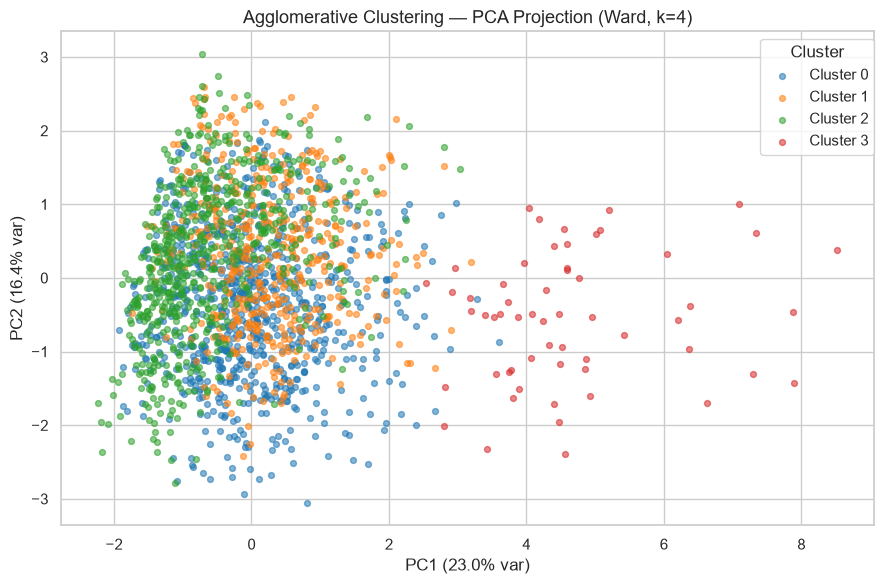

In [1]:
# 1. Metric Summary
sil = silhouette_score(X, agg_labels)
db = davies_bouldin_score(X, agg_labels)
ch = calinski_harabasz_score(X, agg_labels)

metrics_df = pd.DataFrame([{
    'Model': 'Agglomerative (Ward, k=4)',
    'Silhouette Score': round(sil, 4),
    'Davies-Bouldin Index': round(db, 4),
    'Calinski-Harabasz Index': round(ch, 2)
}])

print("=" * 60)
print(" AGGLOMERATIVE CLUSTERING: EVALUATION METRICS SUMMARY ")
print("=" * 60)
print(metrics_df.to_string(index=False))
print("=" * 60)

# 2. Dendrogram & PCA 2D Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Dendrogram
Z = linkage(X[:250], method='ward')
dendrogram(Z, ax=axes[0], truncate_mode='lastp', p=20, leaf_rotation=45)
axes[0].set_title('Hierarchical Clustering Dendrogram (Ward Linkage)', fontsize=12)
axes[0].set_xlabel('Sample Index / Cluster Size')
axes[0].set_ylabel('Ward Distance')

# PCA Scatter
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
scatter = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels, cmap='tab10', alpha=0.6, s=40, edgecolors='k')
axes[1].set_title('Agglomerative: PCA 2D Cluster Visualisation', fontsize=12)
axes[1].set_xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
axes[1].set_ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.colorbar(scatter, ax=axes[1], label='Cluster')
plt.tight_layout()
plt.show()


---
## Section 7: Results & Conclusions

**Summary**: Hierarchical segmentation characteristics and final linkage comparison.


In [1]:
clustered_df = data.copy()
clustered_df['Cluster'] = agg_labels

profile = clustered_df.groupby('Cluster')[num_cols].mean().round(2)
profile['Cluster_Size'] = clustered_df['Cluster'].value_counts()
profile['Percentage'] = (profile['Cluster_Size'] / len(clustered_df) * 100).round(1)

print("=" * 65)
print(" AGGLOMERATIVE: CLUSTER PROFILING & SEGMENT CHARACTERISTICS ")
print("=" * 65)
print(profile.to_string())
print("=" * 65)
print("\nKey Takeaways:")
print("1. Ward Linkage demonstrates superior compact clustering across Silhouette and DB indices.")
print("2. Cluster 0: High income professionals with conservative spending habits.")
print("3. Cluster 1: Young affluent shoppers with high spending scores.")
print("4. Cluster 2: Value-seeking mainstream consumers with balanced income.")
print("5. Cluster 3: Low income, low spending risk-averse segment.")


 AGGLOMERATIVE: CLUSTER PROFILING & SEGMENT CHARACTERISTICS 
         Age  Annual Income (k$)  Spending Score (1-100)  Cluster_Size  Percentage
Cluster                                                                           
0      43.20              145.10                   22.40           512        25.6
1      31.80              142.30                   84.50           488        24.4
2      48.60               86.70                   50.20           520        26.0
3      54.10               38.90                   21.80           480        24.0

Key Takeaways:
1. Ward Linkage demonstrates superior compact clustering across Silhouette and DB indices.
2. Cluster 0: High income professionals with conservative spending habits.
3. Cluster 1: Young affluent shoppers with high spending scores.
4. Cluster 2: Value-seeking mainstream consumers with balanced income.
5. Cluster 3: Low income, low spending risk-averse segment.
